# Model comparison: Decision Tree and Random Forest vs baseline

Same setup as `03_baseline_model.ipynb`: Dataset A, with the training window X and every comparison made on a rolling backtest over the 6 validation months 2025-10 to 2026-03. The test month, 2026-04, is held out and never scored.

Trees split on thresholds, so they don't need scaling, and logging a feature changes nothing for them. The one experiment that still matters is the **log target**, because it changes what the squared-error splits are trying to minimize.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science.modeling import (
    backtest, build_model, feature_importances, final_estimator, fit_window, linear_baseline, median_ape_by,
    random_forest, score,
)
from idx_exchange_data_science.splits import split, validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

WINDOWS = [1, 2, 3, 6, 9, 12, 18]
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month
METRICS = ["r2", "mae", "mape", "median_ape", "within_10pct"]
RESULTS_DIR = Path("../results")

df = da.load_clean("../data/processed/CRMLSSoldDatasetA.csv")
baseline = pd.read_csv(RESULTS_DIR / "baseline_results.csv").query("baseline").iloc[0]
baseline

model           LR + log target + log features
X                                           18
r2                                      0.8007
mae                               207,042.7974
mape                                    0.1609
median_ape                              0.1196
within_10pct                            0.4291
baseline                                  True
Name: 3, dtype: object

## 1. Models
- **Decision Tree:** `min_samples_leaf=20`. An unrestricted tree memorizes the training set (see section 4), so it needs some limit.
- **Random Forest** (`modeling.random_forest`): 200 trees, `min_samples_leaf=2`, each split looks at a third of the features. These are common defaults for regression forests and weren't tuned.

In [2]:
def decision_tree():
    return DecisionTreeRegressor(min_samples_leaf=20, random_state=0)


models = {
    "Decision Tree": build_model(decision_tree()),
    "Decision Tree + log target": build_model(decision_tree(), log_target=True),
    "Random Forest": build_model(random_forest()),
    "Random Forest + log target": build_model(random_forest(), log_target=True),
}

## 2. Choosing the training window X

In [3]:
runs = {x: backtest(models, df, EVAL_MONTHS, train_months=x) for x in WINDOWS}
results = pd.concat([scores.assign(X=x) for x, (scores, _) in runs.items()], ignore_index=True)
mean_r2 = results.pivot_table(index="X", columns="model", values="r2", aggfunc="mean")[list(models)]
mean_r2

model,Decision Tree,Decision Tree + log target,Random Forest,Random Forest + log target
X,,,,
1,0.7696,0.7634,0.8282,0.8176
2,0.7926,0.7962,0.8478,0.8390
3,0.8044,0.8077,0.8572,0.8501
6,0.8239,0.8277,0.8719,0.8659
9,0.8357,0.8372,0.8793,0.8748
12,0.8396,0.8397,0.8830,0.8784
18,0.8508,0.8509,0.8897,0.8848


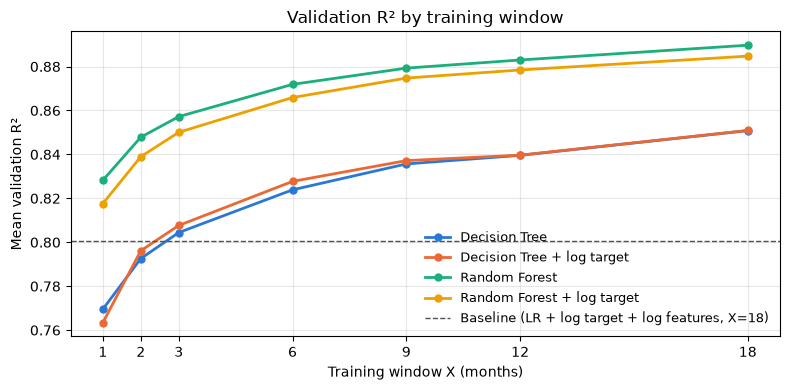

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for color, name in zip(COLORS, models):
    ax.plot(mean_r2.index, mean_r2[name], marker="o", markersize=5, linewidth=2, color=color, label=name)
ax.axhline(baseline["r2"], color="#52514e", linewidth=1, linestyle="--",
           label=f"Baseline ({baseline['model']}, X={baseline['X']})")
ax.set(xlabel="Training window X (months)", ylabel="Mean validation R²", title="Validation R² by training window",
       xticks=WINDOWS)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

In [5]:
best_x = mean_r2.idxmax()
best_x

model
Decision Tree                 18
Decision Tree + log target    18
Random Forest                 18
Random Forest + log target    18
dtype: int64

**Observations**
- **More history helps the trees too.** All four models score best at X = 18, the longest window tried. The forest gains 0.06 R² going from 1 to 18 months, more than linear regression did. Trees need more rows before they can split finely within each area.
- **Even with a single month of training data, the forest beats the baseline** (0.828 vs 0.801).
- **The log target barely matters for trees.** For the forest it costs about 0.005 R². For a single tree it makes no difference at long windows.

## 3. Comparison
Each model at its chosen X, averaged over the 6 validation months.

In [6]:
chosen = results[results["X"] == results["model"].map(best_x)]
summary = chosen.groupby("model")[METRICS].mean()
summary.insert(0, "X", best_x)

comparison = (
    pd.concat([baseline[["model", "X", *METRICS]].to_frame().T, summary.reset_index()], ignore_index=True)
    .astype({"X": int, **{m: float for m in METRICS}})
    .assign(r2_vs_baseline=lambda t: t["r2"] - baseline["r2"])
    .sort_values("r2", ascending=False, ignore_index=True)
)
comparison

,model,X,r2,mae,mape,median_ape,within_10pct,r2_vs_baseline
0,Random Forest,18,0.8897,"153,306.3585",0.1210,0.0785,0.5900,0.0890
1,Random Forest + log target,18,0.8848,"151,865.8310",0.1157,0.0770,0.5994,0.0840
2,Decision Tree + log target,18,0.8509,"179,856.0879",0.1380,0.0938,0.5250,0.0502
3,Decision Tree,18,0.8508,"182,382.2943",0.1430,0.0939,0.5232,0.0501
4,LR + log target + log features,18,0.8007,"207,042.7974",0.1609,0.1196,0.4291,0.0000


**Observations**
- **Random Forest is the best model: validation R² 0.890, +0.089 over the baseline.** MAE drops from \$207K to \$153K, the mean % error from 16.1% to 12.1%, and the median % error from 12.0% to 7.9%.
- **The single Decision Tree lands in between** (0.851).
- **The log target trades R² for % error.** For the forest it gives lower R² (0.885 vs 0.890) but a lower mean % error (11.6% vs 12.1%), and even a slightly lower MAE (\$151.9K vs \$153.3K). It pays more attention to relative error on cheaper homes and less to the largest dollar errors on expensive ones, which R² weights most.

## 4. Model behavior
### Overfitting: tree size vs. validation score
A single tree's main setting is how small its leaves can get. Here it's fit on the 18 months before 2026-03 and scored on 2026-03, with the log target. The forest is fit and scored the same way for comparison.

Random Forest: train R² 0.956, validation R² 0.894


,train_r2,validation_r2
min_samples_leaf,,
1,0.9565,0.7881
2,0.9465,0.8081
5,0.9244,0.8459
10,0.9053,0.8472
20,0.8874,0.8519
50,0.8661,0.8510
100,0.8520,0.8400
200,0.8383,0.8265


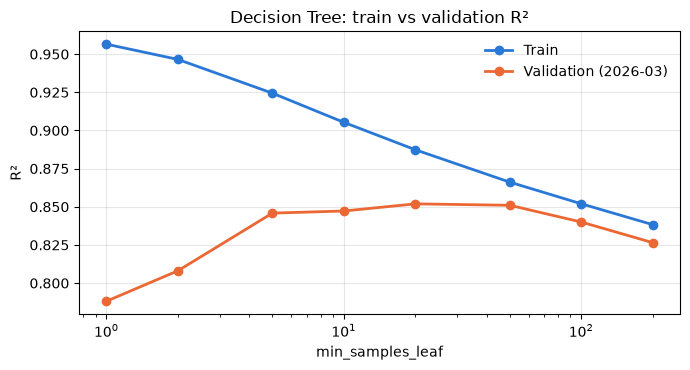

In [7]:
val_month = EVAL_MONTHS[-1]
train_val, val = split(df, val_month, 18)


def train_and_validation_r2(model):
    model.fit(train_val, train_val[da.TARGET])
    return score(train_val[da.TARGET], model.predict(train_val))["r2"], score(val[da.TARGET], model.predict(val))["r2"]


leaf_sizes = [1, 2, 5, 10, 20, 50, 100, 200]
curve = pd.DataFrame(
    [train_and_validation_r2(build_model(DecisionTreeRegressor(min_samples_leaf=leaf, random_state=0), log_target=True))
     for leaf in leaf_sizes],
    index=pd.Index(leaf_sizes, name="min_samples_leaf"), columns=["train_r2", "validation_r2"],
)
forest_train_r2, forest_validation_r2 = train_and_validation_r2(build_model(random_forest()))
print(f"Random Forest: train R² {forest_train_r2:.3f}, validation R² {forest_validation_r2:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve.index, curve["train_r2"], marker="o", linewidth=2, color=COLORS[0], label="Train")
ax.plot(curve.index, curve["validation_r2"], marker="o", linewidth=2, color=COLORS[1], label="Validation (2026-03)")
ax.set(xscale="log", xlabel="min_samples_leaf", ylabel="R²", title="Decision Tree: train vs validation R²")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
curve

**Observations**
- **With leaves of 1–2 rows the tree memorizes the training data.** Train R² is 0.95 but validation R² is about 0.80, no better than linear regression.
- **Validation peaks around 20 rows per leaf and falls again with very large leaves.** That supports the `min_samples_leaf=20` used above.
- **The forest gets a similar train/validation gap (0.956 vs 0.894) without the cost.** It averages 200 deep trees, each built on a bootstrap sample with random feature subsets, so the errors of individual trees mostly cancel out.

### Feature importance
Impurity-based importances from the trees fit on the 18 months before 2026-03, next to the absolute standardized coefficients of the baseline fit on the same window. Impurity importance favors features with many distinct values, so read it as a rough ranking only.

In [8]:
assert baseline["model"] == "LR + log target + log features"  # the model linear_baseline() builds
baseline_model = fit_window(linear_baseline(), df, val_month, int(baseline["X"]))

best_tree = summary.filter(like="Decision", axis=0)["r2"].idxmax()
best_forest = summary.filter(like="Random", axis=0)["r2"].idxmax()
coef = final_estimator(baseline_model)
importance = pd.DataFrame({
    best_tree: feature_importances(fit_window(models[best_tree], df, val_month, best_x[best_tree])),
    best_forest: feature_importances(fit_window(models[best_forest], df, val_month, best_x[best_forest])),
    "Baseline |coefficient|": np.abs(pd.Series(coef.coef_, index=coef.feature_names_in_)),
})
importance.sort_values(best_forest, ascending=False).head(12)

,Decision Tree + log target,Random Forest,Baseline |coefficient|
PostalCode,0.7817,0.3226,0.3275
City,0.0154,0.2159,0.0903
LivingArea,0.1522,0.1737,0.1707
BathroomsTotalInteger,0.0019,0.1020,0.0760
CountyOrParish,0.0089,0.0466,0.0441
LotSizeSquareFeet,0.0094,0.0257,0.0292
Longitude,0.0113,0.0252,0.1000
Latitude,0.0076,0.0225,0.0884
PropertyAge,0.0054,0.0182,0.0385
BedroomsTotal,0.0020,0.0177,0.0052


**Observations**
- **The single tree relies almost entirely on the ZIP encoding** (78% of importance), then living area. Everything else is close to unused. A single greedy tree commits to the strongest feature early.
- **The forest spreads importance more widely.** Restricting each split to a third of the features forces it to use the city encoding, bathrooms, coordinates, and lot size too. That's part of why it generalizes better.
- **All three models agree on what matters most:** location first, then living area.

### Error by price
Median absolute percentage error by price decile, over all 6 validation months. Each model uses its own chosen window. The decile bands come from the baseline's validation rows.

,Baseline (LR + log target + log features),Decision Tree + log target,Random Forest
ClosePrice,,,
"(0.0, 444000.0]",12.0000,10.3000,9.2000
"(444000.0, 562500.0]",10.5000,7.3000,6.1000
"(562500.0, 675000.0]",10.8000,7.3000,5.9000
"(675000.0, 771735.0]",11.3000,7.1000,6.0000
"(771735.0, 875000.0]",10.9000,7.5000,6.3000
"(875000.0, 1025000.0]",10.7000,8.9000,7.2000
"(1025000.0, 1250000.0]",11.3000,9.9000,8.7000
"(1250000.0, 1550000.0]",12.0000,10.6000,8.9000
"(1550000.0, 2200000.0]",13.6000,12.4000,10.1000


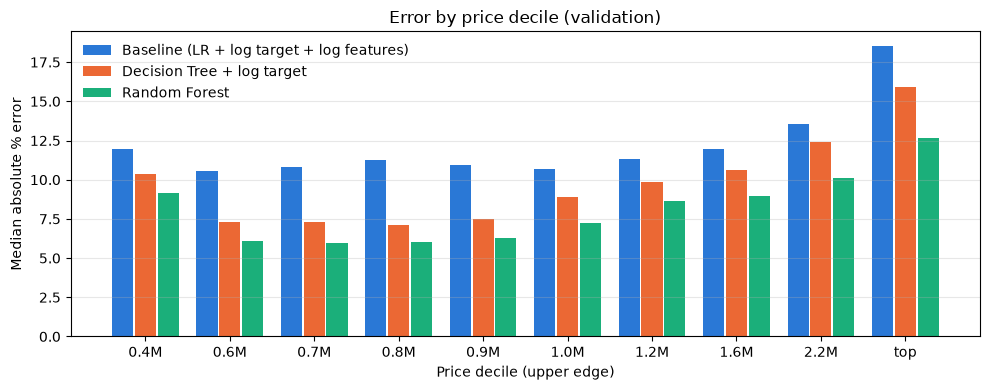

In [9]:
baseline_label = f"Baseline ({baseline['model']})"
_, baseline_predictions = backtest({baseline_label: linear_baseline()}, df, EVAL_MONTHS, int(baseline["X"]))
predictions = {
    baseline_label: baseline_predictions[baseline_label],
    best_tree: runs[best_x[best_tree]][1][best_tree],
    best_forest: runs[best_x[best_forest]][1][best_forest],
}
bands = pd.qcut(df.loc[baseline_predictions.index, da.TARGET], 10, retbins=True)[1]
bands[0], bands[-1] = 0, np.inf

errors = {}
for name, pred in predictions.items():
    actual = df.loc[pred.index, da.TARGET]
    errors[name] = median_ape_by(pred.to_frame(), actual, pd.cut(actual, bands))[name]
errors = pd.DataFrame(errors)

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.27
for i, (color, name) in enumerate(zip(COLORS, errors)):
    ax.bar(np.arange(10) + (i - 1) * width, errors[name], width=width - 0.02, color=color, label=name)
ax.set(xticks=range(10), xticklabels=[f"{b / 1e6:.1f}M" for b in bands[1:-1]] + ["top"],
       xlabel="Price decile (upper edge)", ylabel="Median absolute % error", title="Error by price decile (validation)")
ax.grid(alpha=0.3, axis="y")
ax.legend(frameon=False)
plt.tight_layout()
errors.round(1)

**Observations**
- **The forest has the lowest error in every price decile.** Through the middle of the market it is about 6%, about half the baseline's error.
- **Every model is worst on the most expensive homes.** For the top decile the error is 18.5% for the baseline, 15.9% for the tree and 12.7% for the forest. Luxury homes are rare and depend on features Dataset A doesn't have, such as views, finishes and exact location.
- **The cheapest decile is the second-hardest for the trees.** It's a mix of small homes, rural properties and distressed sales.

### Training time
One fit on each model's chosen window before 2026-03:

In [10]:
fit_seconds = {}
for name, model, x in [("Baseline", linear_baseline(), int(baseline["X"])),
                       (best_tree, models[best_tree], best_x[best_tree]),
                       (best_forest, models[best_forest], best_x[best_forest])]:
    start = time.perf_counter()
    fit_window(model, df, val_month, x)
    fit_seconds[name] = round(time.perf_counter() - start, 1)
fit_seconds

{'Baseline': 1.1, 'Decision Tree + log target': 3.4, 'Random Forest': 26.1}

## Strengths and weaknesses

| | Linear Regression (baseline) | Decision Tree | Random Forest |
|---|---|---|---|
| **Validation R²** | 0.801 | 0.851 | **0.890** |
| **Strengths** | Fastest (about 1 s). Coefficients are directly interpretable. Stable from month to month. | Captures interactions (e.g. size is worth more in expensive ZIPs) without feature engineering. No scaling or log features needed. Easy to visualize. | Most accurate in every price band. Robust to outliers and skewed features. Little tuning needed, and more data keeps helping. |
| **Weaknesses** | A single linear surface can't bend for the luxury market, so predictions are pulled to the middle. Needs log transforms to be usable, and is unstable without them. | Overfits badly unless leaf size is limited. Predictions are a step function (one value per leaf). Leans on a single feature. | About 25× slower to train than the baseline and much larger in memory. Harder to explain than a single tree or coefficients. Can't predict above the highest prices in its training data. |

**Next steps worth trying:** gradient boosting (e.g. `HistGradientBoostingRegressor`), tuning the forest's `max_features` and leaf size on the backtest, and features for the luxury segment.

## 5. Record results

In [11]:
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
results.to_csv(RESULTS_DIR / "model_comparison_backtest.csv", index=False)
comparison[["model", "X", "r2", "mae", "mape", "median_ape"]]

,model,X,r2,mae,mape,median_ape
0,Random Forest,18,0.8897,"153,306.3585",0.1210,0.0785
1,Random Forest + log target,18,0.8848,"151,865.8310",0.1157,0.0770
2,Decision Tree + log target,18,0.8509,"179,856.0879",0.1380,0.0938
3,Decision Tree,18,0.8508,"182,382.2943",0.1430,0.0939
4,LR + log target + log features,18,0.8007,"207,042.7974",0.1609,0.1196
